# Real-Time PI Data Retrieval & Press 1 Quality Analysis

This notebook retrieves real-time process & lab quality data via the **MI Cube API** (`InterpolatedValue/MultiTag/`) from the **AVEVA PI Server (`VPKGDRBPPI01`)**.
The goal is to analyze **Press 1 pulp quality** (Kappa, Viscosity, Brightness) and plot **Probability Density Bell Curves** and **Heatmaps** directly.

In [181]:
import requests
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style with thinner font weight
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = ['Tahoma', 'DejaVu Sans']
plt.rcParams['font.weight'] = 'normal'
plt.rcParams['axes.titleweight'] = 'normal'
plt.rcParams['axes.labelweight'] = 'normal'
plt.rcParams['axes.unicode_minus'] = False
print(" Libraries imported successfully.")

 Libraries imported successfully.


## 1. Configure API Endpoint & Target PI Tags

In [182]:
# MI Cube API Endpoint for multi-tag interpolated data retrieval
MI_CUBE_API_URL = "https://micube.scg.com/v2/api/Datacenter/PIServer/InterpolatedValue/MultiTag/"
API_TOKEN = "76ED1A0F-7386-432B-B586-5A8304AE20FB"
PI_SERVER = "VPKGDRBPPI01"

# Target PI Tags (Batch Statuses + Press 1 Lab Quality Metrics)
TAGS = [
    "PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_Status",
    "PPPC_DP_Cooking.B2_Discharge_FinalTime_Press1_Status",
    "PPPC_DP_Cooking.B3_Discharge_FinalTime_Press1_Status",
    "PPPC_DP_Cooking.B4_Discharge_FinalTime_Press1_Status",
    "PULP-LINE2-KAPPA-PRESS1",
    "PULP-LINE2-VISCOSITY-PRESS1",
    "PULP-LINE2-BRIGHTNESS-PRESS1",
    "PM2.105FIC303:MV", # WHLiqu to DilSrew
    "PM2.305FIC036:MV",  # MP Steam Pulp Heat
    "PM2.Prod.ODL", # Production ODL
    "PM2.105NIC207:MV", #Press 1 Feed Cons
    "PM2.106FIC006:MV", #Deknotting Feed Flow
    
]

# Time range settings
START_TIME = "2026-08-01 00:00:00"
END_TIME = "2026-10-01 00:00:00"
INTERVAL = "15m"

# Real quality SOP limits (Lower, Upper) — single source of truth used across all cells
LAB_SOP_LIMITS = {
    "PULP-LINE2-KAPPA-PRESS1": (7.5, 8.5),
    "PULP-LINE2-VISCOSITY-PRESS1": (680, 710),
    "PULP-LINE2-BRIGHTNESS-PRESS1": (37, 40),
}

print(f"Target Endpoint : {MI_CUBE_API_URL}")
print(f"Total Tags      : {len(TAGS)}")

Target Endpoint : https://micube.scg.com/v2/api/Datacenter/PIServer/InterpolatedValue/MultiTag/
Total Tags      : 12


## 2. Execute HTTP POST Request to MI Cube API

In [183]:
payload = {
    "token": API_TOKEN,
    "server": PI_SERVER,
    "tags": TAGS,
    "start_time": START_TIME,
    "end_time": END_TIME,
    "interval": INTERVAL
}

headers = {
    'Content-Type': 'application/json',
    'Accept': 'application/json'
}
    
print("Sending POST Request to MI Cube API...")
try:
    response = requests.post(MI_CUBE_API_URL, json=payload, headers=headers, timeout=30)
    print(f"Status Code: {response.status_code}")
    if response.status_code == 200:
        data = response.json()
        print(" Fetch Success! Response Preview:")
        print(json.dumps(data, indent=2)[:500])
    else:
        print(f" API Request Failed: {response.text}")
except Exception as e:
    print(f" Connection Error: {e}")

Sending POST Request to MI Cube API...
Status Code: 200
 Fetch Success! Response Preview:
{
  "status": "success",
  "message": "Interpolated values retrieved successfully",
  "results": {
    "PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_Status": [
      {
        "timestamp": "2026-08-01T00:00:00+00:00",
        "value": 0.06010517799352751,
        "description": "",
        "unit": ""
      },
      {
        "timestamp": "2026-08-01T00:15:00+00:00",
        "value": 0.06540857605177994,
        "description": "",
        "unit": ""
      },
      {
        "timestamp": "2026-08


## 3. Parse JSON Response into Pandas DataFrame

In [184]:
if 'response' in locals() and response.status_code == 200:
    # Parse JSON structure
    if isinstance(data, dict) and 'results' in data:
        raw_results = data['results']
    elif isinstance(data, list):
        raw_results = data
    else:
        raw_results = [data]
        
    # Standardize long-format DataFrame
    if isinstance(raw_results, dict):
        df_list = []
        for tag, records in raw_results.items():
            tmp = pd.DataFrame(records)
            tmp['tag'] = tag
            df_list.append(tmp)
        df_long = pd.concat(df_list, ignore_index=True)
    else:
        df_long = pd.DataFrame(raw_results)
        
    print(f" Raw Data Parsed: {len(df_long)} records.")
    display(df_long.head(10))
else:
    print(" No response data available to process.")

 Raw Data Parsed: 70284 records.


,timestamp,value,description,unit,tag
0,2026-08-01T00:00:00+00:00,0.060105,,,PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_...
1,2026-08-01T00:15:00+00:00,0.065409,,,PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_...
2,2026-08-01T00:30:00+00:00,0.070712,,,PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_...
3,2026-08-01T00:45:00+00:00,0.076015,,,PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_...
4,2026-08-01T01:00:00+00:00,0.081319,,,PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_...
5,2026-08-01T01:15:00+00:00,0.086622,,,PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_...
6,2026-08-01T01:30:00+00:00,0.091926,,,PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_...
7,2026-08-01T01:45:00+00:00,0.097229,,,PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_...
8,2026-08-01T02:00:00+00:00,0.102532,,,PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_...
9,2026-08-01T02:15:00+00:00,0.107836,,,PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_...


## 4. Press 1 Pulp Quality Analysis & Bell Curve Visualizations

In [185]:
# Data Reshaping, Specific Consumption Calculation & Active Digester Assignment
if 'df_long' in locals() and not df_long.empty:
    # 1. Standardize column names
    col_map = {col: col.lower() for col in df_long.columns}
    df_long = df_long.rename(columns=col_map)
    
    # 2. Pivot long format to wide format (Timestamp as Index, Tags as Columns)
    time_col = 'timestamp' if 'timestamp' in df_long.columns else 'time'
    tag_col = 'tag' if 'tag' in df_long.columns else 'tagname'
    val_col = 'value' if 'value' in df_long.columns else 'val'
    
    df_wide = df_long.pivot_table(index=time_col, columns=tag_col, values=val_col, aggfunc='first').reset_index()
    df_wide[time_col] = pd.to_datetime(df_wide[time_col])
    df_wide = df_wide.sort_values(time_col).reset_index(drop=True)
    
    # 3. Coerce numeric columns
    for col in df_wide.columns:
        if col != time_col:
            df_wide[col] = pd.to_numeric(df_wide[col], errors='coerce')
            
    # 4. Map Active Digester (1 - 4)
    status_cols = {
        1: 'PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_Status',
        2: 'PPPC_DP_Cooking.B2_Discharge_FinalTime_Press1_Status',
        3: 'PPPC_DP_Cooking.B3_Discharge_FinalTime_Press1_Status',
        4: 'PPPC_DP_Cooking.B4_Discharge_FinalTime_Press1_Status'
    }
    
    def get_active_digester(row):
        # Status must equal its own digester number exactly (B1 == 1, B2 == 2, ...)
        matches = [dig_id for dig_id, col in status_cols.items() if col in row and row[col] == dig_id]
        if len(matches) == 1:
            return matches[0]
        return np.nan  # NaN if no digester matches, or more than one (cannot tell which)
        
    df_wide['Digester_ID'] = df_wide.apply(get_active_digester, axis=1)

    # 5. Compute Specific Consumption Metrics (Specific White Liquor & Specific Steam)
    wl_tag = "PM2.105FIC303:MV"
    steam_tag = "PM2.305FIC036:MV"
    prod_tag = "PM2.Prod.ODL"

    if prod_tag in df_wide.columns:
        temp_prod = df_wide[prod_tag].copy()
        temp_prod[temp_prod <= 0] = np.nan
        
        if wl_tag in df_wide.columns:
            df_wide['Specific WHLiqu Consumption (m3_ADT)'] = 24.0 * df_wide[wl_tag] / temp_prod
        if steam_tag in df_wide.columns:
            df_wide['Specific Steam Consumption (t_ADT)'] = 24.0 * df_wide[steam_tag] / temp_prod

    print(" Real-time API Data Reshaped & Digester Assigned Successfully.")
    print("Batch Counts per Digester:")
    print(df_wide['Digester_ID'].value_counts().sort_index())
    display(df_wide.head(10))
else:
    # Fallback to local clustered batch signatures for demonstration
    print(" Loading local dataset `df_clustered_batches.xlsx` for Press 1 Quality Analysis...")
    df_wide = pd.read_excel('df_clustered_batches.xlsx')
    # Ensure Digester_ID is numeric for fallback data
    if 'Digester_ID' in df_wide.columns:
        df_wide['Digester_ID'] = pd.to_numeric(df_wide['Digester_ID'], errors='coerce')
    print(f"Loaded {len(df_wide)} records.")
    print("Batch Counts per Digester:")
    print(df_wide['Digester_ID'].value_counts().sort_index())

 Real-time API Data Reshaped & Digester Assigned Successfully.
Batch Counts per Digester:
Digester_ID
1.0    1029
2.0    1316
3.0    1239
4.0    1017
Name: count, dtype: int64


tag,timestamp,PM2.105FIC303:MV,PM2.105NIC207:MV,PM2.106FIC006:MV,PM2.305FIC036:MV,PM2.Prod.ODL,PPPC_DP_Cooking.B1_Discharge_FinalTime_Press1_Status,PPPC_DP_Cooking.B2_Discharge_FinalTime_Press1_Status,PPPC_DP_Cooking.B3_Discharge_FinalTime_Press1_Status,PPPC_DP_Cooking.B4_Discharge_FinalTime_Press1_Status,PULP-LINE2-BRIGHTNESS-PRESS1,PULP-LINE2-KAPPA-PRESS1,PULP-LINE2-VISCOSITY-PRESS1,Digester_ID,Specific WHLiqu Consumption (m3_ADT),Specific Steam Consumption (t_ADT)
0,2026-08-01 00:00:00+00:00,1.346662,3.851953,535.335938,1.095254,276.456970,0.060105,2.0,0.106690,0.0,35.000000,9.00000,816.000,2.0,0.116907,0.095082
1,2026-08-01 00:15:00+00:00,1.341825,3.859922,463.257812,1.037422,267.233093,0.065409,2.0,0.095093,0.0,34.887501,9.09375,813.875,2.0,0.120508,0.093170
2,2026-08-01 00:30:00+00:00,1.336989,3.954141,561.585938,1.073652,269.881622,0.070712,0.0,0.083496,4.0,34.775002,9.18750,811.750,4.0,0.118896,0.095478
3,2026-08-01 00:45:00+00:00,1.354461,3.955312,555.898438,1.106875,275.005951,0.076015,0.0,0.071900,4.0,34.662498,9.28125,809.625,4.0,0.118205,0.096598
4,2026-08-01 01:00:00+00:00,1.336468,3.921172,566.589844,1.061758,273.401154,0.081319,0.0,0.060303,4.0,34.549999,9.37500,807.500,4.0,0.117319,0.093204
5,2026-08-01 01:15:00+00:00,1.343258,3.959531,567.109375,1.153496,271.175354,0.086622,0.0,0.048706,4.0,34.437500,9.46875,805.375,4.0,0.118883,0.102089
6,2026-08-01 01:30:00+00:00,1.340305,3.878438,553.929688,1.096895,272.017303,0.091926,0.0,0.037109,4.0,34.324997,9.56250,803.250,4.0,0.118255,0.096779
7,2026-08-01 01:45:00+00:00,1.333569,3.893047,498.750000,1.040703,272.247803,0.097229,0.0,0.025513,4.0,34.212498,9.65625,801.125,4.0,0.117561,0.091743
8,2026-08-01 02:00:00+00:00,1.333478,3.831094,494.593750,1.155137,264.575775,0.102532,0.0,0.013916,4.0,34.099998,9.75000,799.000,4.0,0.120961,0.104784
9,2026-08-01 02:15:00+00:00,1.361633,3.945468,552.453125,1.046719,279.153839,0.107836,0.0,0.002319,4.0,34.549999,9.84375,796.875,4.0,0.117065,0.089991


### 5. Plot Press 1 Quality Probability Density Bell Curves (KDE Plots)

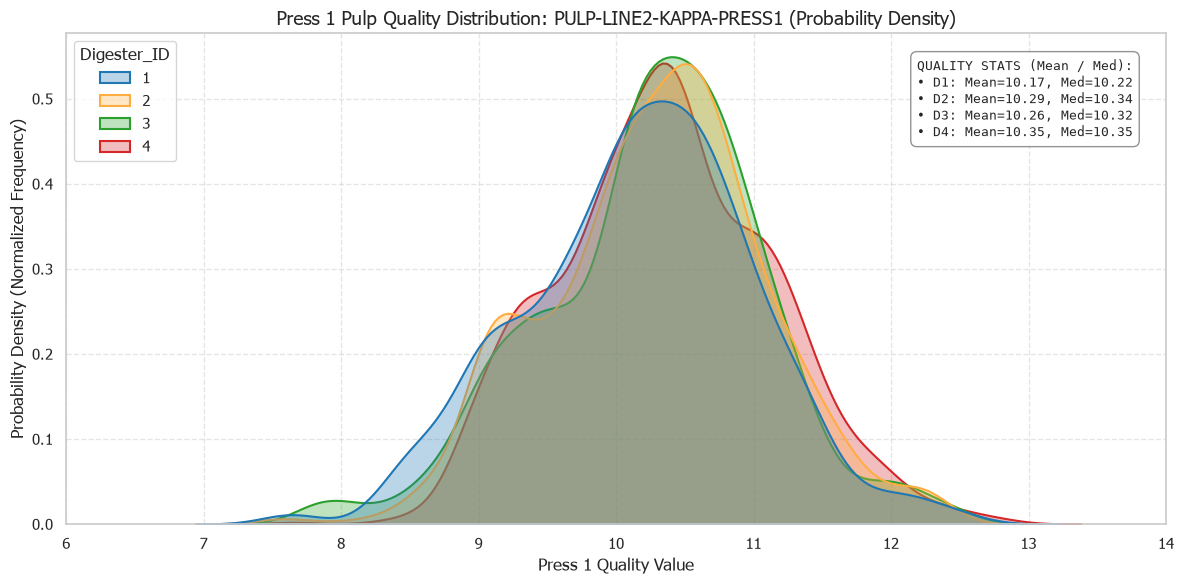

In [186]:
# Identify Press 1 quality parameter columns
kappa_col = [c for c in df_wide.columns if 'KAPPA' in c.upper() or 'Kappa' in c][0] if any('KAPPA' in c.upper() or 'Kappa' in c for c in df_wide.columns) else None
cons_col = [c for c in df_wide.columns if 'Press 1 Feed Cons' in c or 'CONS' in c.upper()][0] if any('CONS' in c.upper() for c in df_wide.columns) else None

palette = {1: '#1f77b4', 2: "#ffad41", 3: '#2ca02c', 4: '#d62728'}
digester_order = [1, 2, 3, 4]

# 1. Plot Kappa / Quality Metric Bell Curve
plt.figure(figsize=(12, 6))
if kappa_col and kappa_col in df_wide.columns:
    ax = sns.kdeplot(
        data=df_wide.dropna(subset=[kappa_col]),
        x=kappa_col,
        hue='Digester_ID',
        hue_order=digester_order,
        palette=palette,
        fill=True,
        alpha=0.3,
        common_norm=False,
        linewidth=1.5
        
    )
    plt.xlim(6, 14)  # Compress X-axis view
    
    # Calculate Mean and Median per Digester
    valid_data = df_wide.dropna(subset=[kappa_col])
    stats_text = "QUALITY STATS (Mean / Med):\n"
    for dig in digester_order:
        dig_vals = valid_data[valid_data['Digester_ID'] == dig][kappa_col]
        if len(dig_vals) > 0:
            m_val = dig_vals.mean()
            med_val = dig_vals.median()
            stats_text += f"• D{dig}: Mean={m_val:.2f}, Med={med_val:.2f}\n"

    # Add text box in upper right corner
    ax.text(
        0.97, 0.95, stats_text.strip(),
        transform=ax.transAxes,
        fontsize=9,
        fontfamily='monospace',
        verticalalignment='top',
        horizontalalignment='right',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='gray', alpha=0.85)
    )

    plt.title(f'Press 1 Pulp Quality Distribution: {kappa_col} (Probability Density)', fontsize=14, fontweight='normal')
    plt.xlabel('Press 1 Quality Value', fontsize=12, fontweight='normal')
    plt.ylabel('Probability Density (Normalized Frequency)', fontsize=12, fontweight='normal')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
else:
    print(" Kappa column not found in dataset. Please verify tag mapping.")

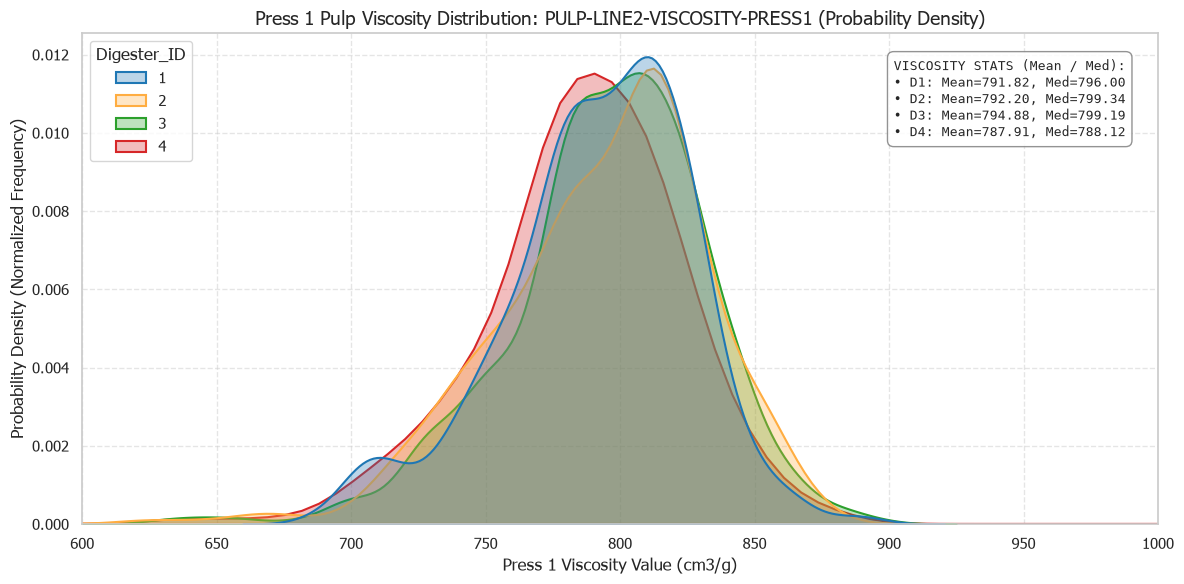

In [187]:
# 2. Plot Viscosity Bell Curve
visc_col = [c for c in df_wide.columns if 'VISCOSITY' in c.upper() or 'Viscosity' in c][0] if any('VISCOSITY' in c.upper() or 'Viscosity' in c for c in df_wide.columns) else None

# Drop sensor spikes before plotting (same range as histogram/boxplot cells)
VISC_FILTER = (400, 2000)
# Adjustable X-axis view range (set to None for auto-scaling)
VISC_XLIM_MIN = 600
VISC_XLIM_MAX = 1000

plt.figure(figsize=(12, 6))
if visc_col and visc_col in df_wide.columns:
    visc_data = df_wide.dropna(subset=[visc_col])
    visc_data = visc_data[(visc_data[visc_col] >= VISC_FILTER[0]) & (visc_data[visc_col] <= VISC_FILTER[1])]
    ax = sns.kdeplot(
        data=visc_data,
        x=visc_col,
        hue='Digester_ID',
        hue_order=digester_order,
        palette=palette,
        fill=True,
        alpha=0.3,
        common_norm=False,
        linewidth=1.5
    )

    if VISC_XLIM_MIN is not None and VISC_XLIM_MAX is not None:
        plt.xlim(VISC_XLIM_MIN, VISC_XLIM_MAX)
    
    # Calculate Mean and Median per Digester (from spike-filtered data)
    valid_data = visc_data
    stats_text = "VISCOSITY STATS (Mean / Med):\n"
    for dig in digester_order:
        dig_vals = valid_data[valid_data['Digester_ID'] == dig][visc_col]
        if len(dig_vals) > 0:
            m_val = dig_vals.mean()
            med_val = dig_vals.median()
            stats_text += f"• D{dig}: Mean={m_val:.2f}, Med={med_val:.2f}\n"

    # Add text box in upper right corner
    ax.text(
        0.97, 0.95, stats_text.strip(),
        transform=ax.transAxes,
        fontsize=9,
        fontfamily='monospace',
        verticalalignment='top',
        horizontalalignment='right',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='gray', alpha=0.85)
    )

    plt.title(f'Press 1 Pulp Viscosity Distribution: {visc_col} (Probability Density)', fontsize=14, fontweight='normal')
    plt.xlabel('Press 1 Viscosity Value (cm3/g)', fontsize=12, fontweight='normal')
    plt.ylabel('Probability Density (Normalized Frequency)', fontsize=12, fontweight='normal')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
else:
    print(" Viscosity column not found in dataset. Please verify tag mapping.")


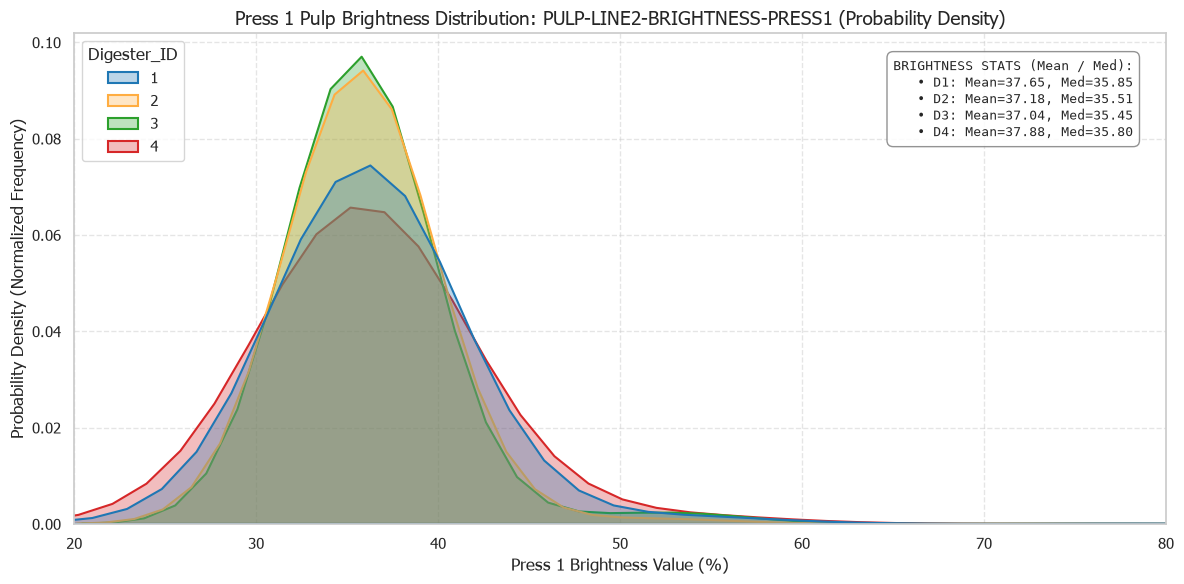

In [188]:
# 3. Plot Brightness Bell Curve
bright_col = [c for c in df_wide.columns if 'BRIGHTNESS' in c.upper() or 'Brightness' in c][0] if any('BRIGHTNESS' in c.upper() or 'Brightness' in c for c in df_wide.columns) else None

plt.figure(figsize=(12, 6))
if bright_col and bright_col in df_wide.columns:
    ax = sns.kdeplot(
        data=df_wide.dropna(subset=[bright_col]),
        x=bright_col,
        hue='Digester_ID',
        hue_order=digester_order,
        palette=palette,
        fill=True,
        alpha=0.3,
        common_norm=False,
        linewidth=1.5
    )
    
    # Calculate Mean and Median per Digester
    valid_data = df_wide.dropna(subset=[bright_col])
    stats_text = "BRIGHTNESS STATS (Mean / Med):\n"
    for dig in digester_order:
        dig_vals = valid_data[valid_data['Digester_ID'] == dig][bright_col]
        if len(dig_vals) > 0:
            m_val = dig_vals.mean()
            med_val = dig_vals.median()
            stats_text += f"• D{dig}: Mean={m_val:.2f}, Med={med_val:.2f}\n"

    # Add text box in upper right corner
    ax.text(
        0.97, 0.95, stats_text.strip(),
        transform=ax.transAxes,
        fontsize=9,
        fontfamily='monospace',
        verticalalignment='top',
        horizontalalignment='right',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='gray', alpha=0.85)
    )

    plt.title(f'Press 1 Pulp Brightness Distribution: {bright_col} (Probability Density)', fontsize=14, fontweight='normal')
    plt.xlabel('Press 1 Brightness Value (%)', fontsize=12, fontweight='normal')
    plt.ylabel('Probability Density (Normalized Frequency)', fontsize=12, fontweight='normal')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.xlim(20, 80)
    plt.tight_layout()
    plt.show()
else:
    print(" Brightness column not found in dataset. Please verify tag mapping.")

In [189]:
# Reusable helper: plot a single standard histogram with Mean, Median & SOP band
def plot_quality_histogram(col, label, color, xlim=None, ylim=None, filter_lo=None, filter_hi=None, bins=40, density=False):
    if not col or col not in df_wide.columns:
        print(f" {label} column not found in dataset.")
        return

    ylabel = 'Density (normalized)' if density else 'Frequency (count)'
    vals = df_wide[col].dropna()
    if filter_lo is not None and filter_hi is not None:
        vals = vals[(vals >= filter_lo) & (vals <= filter_hi)]  # drop sensor spikes

    mu, sd = vals.mean(), vals.std()
    lo2, hi2 = mu - 2 * sd, mu + 2 * sd  # 2-sigma band (~95% of data)

    plt.figure(figsize=(10, 5))
    plt.hist(vals, bins=bins, color=color, edgecolor='black', alpha=0.75, density=density)
    plt.axvline(mu, color='red', linestyle='--', linewidth=1.5, label=f'Mean = {mu:.2f}')
    plt.axvline(vals.median(), color='black', linestyle=':', linewidth=1.5, label=f'Median = {vals.median():.2f}')
    plt.axvspan(lo2, hi2, color='purple', alpha=0.08, label=f'±2σ [{lo2:.2f}, {hi2:.2f}]')
    plt.axvline(lo2, color='purple', linestyle='-.', linewidth=1.0)
    plt.axvline(hi2, color='purple', linestyle='-.', linewidth=1.0)

    if col in LAB_SOP_LIMITS:
        sop_lo, sop_hi = LAB_SOP_LIMITS[col]
        plt.axvspan(sop_lo, sop_hi, color='green', alpha=0.12, label=f'SOP {sop_lo}-{sop_hi}')

    if xlim is not None:
        plt.xlim(xlim)
    if ylim is not None:
        plt.ylim(ylim)

    plt.title(f'{label} Histogram  (N = {len(vals)})', fontsize=13, fontweight='normal')
    plt.xlabel(label, fontsize=11)
    plt.ylabel(ylabel, fontsize=11)
    plt.legend(fontsize=9)
    plt.grid(True, linestyle='--', alpha=0.4)
    plt.tight_layout()
    plt.show()


# Reusable helper: 2x2 histograms of one parameter split by Digester (D1-D4)
def plot_quality_hist_by_digester(col, label, color, xlim=None, ylim=None, filter_lo=None, filter_hi=None, bins=40, density=False):
    if not col or col not in df_wide.columns or 'Digester_ID' not in df_wide.columns:
        print(f" {label} column or Digester_ID not found in dataset.")
        return

    ylabel = 'Density (normalized)' if density else 'Frequency (count)'

    digester_order = [1, 2, 3, 4]
    fig, axes = plt.subplots(4, 1, figsize=(10, 16))
    axes = axes.flatten()

    for i, dig in enumerate(digester_order):
        ax = axes[i]
        vals = df_wide[df_wide['Digester_ID'] == dig][col].dropna()
        if filter_lo is not None and filter_hi is not None:
            vals = vals[(vals >= filter_lo) & (vals <= filter_hi)]  # drop sensor spikes

        if len(vals) == 0:
            ax.text(0.5, 0.5, f'No data for D{dig}', ha='center', va='center', color='gray')
            ax.set_title(f'D{dig}', fontsize=12)
            continue

        mu, sd = vals.mean(), vals.std()
        lo2, hi2 = mu - 2 * sd, mu + 2 * sd  # 2-sigma band (~95% of data)

        ax.hist(vals, bins=bins, color=color, edgecolor='black', alpha=0.75, density=density)
        ax.axvline(mu, color='red', linestyle='--', linewidth=1.5, label=f'Mean = {mu:.2f}')
        ax.axvline(vals.median(), color='black', linestyle=':', linewidth=1.5, label=f'Median = {vals.median():.2f}')
        ax.axvspan(lo2, hi2, color='purple', alpha=0.08, label=f'±2σ [{lo2:.2f}, {hi2:.2f}]')
        ax.axvline(lo2, color='purple', linestyle='-.', linewidth=1.0)
        ax.axvline(hi2, color='purple', linestyle='-.', linewidth=1.0)

        if col in LAB_SOP_LIMITS:
            sop_lo, sop_hi = LAB_SOP_LIMITS[col]
            ax.axvspan(sop_lo, sop_hi, color='green', alpha=0.12, label=f'SOP {sop_lo}-{sop_hi}')

        if xlim is not None:
            ax.set_xlim(xlim)
        if ylim is not None:
            ax.set_ylim(ylim)

        ax.set_title(f'D{dig}  (N = {len(vals)})', fontsize=12, fontweight='normal')
        ax.set_xlabel(label, fontsize=10)
        ax.set_ylabel(ylabel, fontsize=10)
        ax.legend(fontsize=8)
        ax.grid(True, linestyle='--', alpha=0.4)

    fig.suptitle(f'{label} Histogram by Digester (D1 - D4)', fontsize=15)
    plt.tight_layout()
    plt.show()


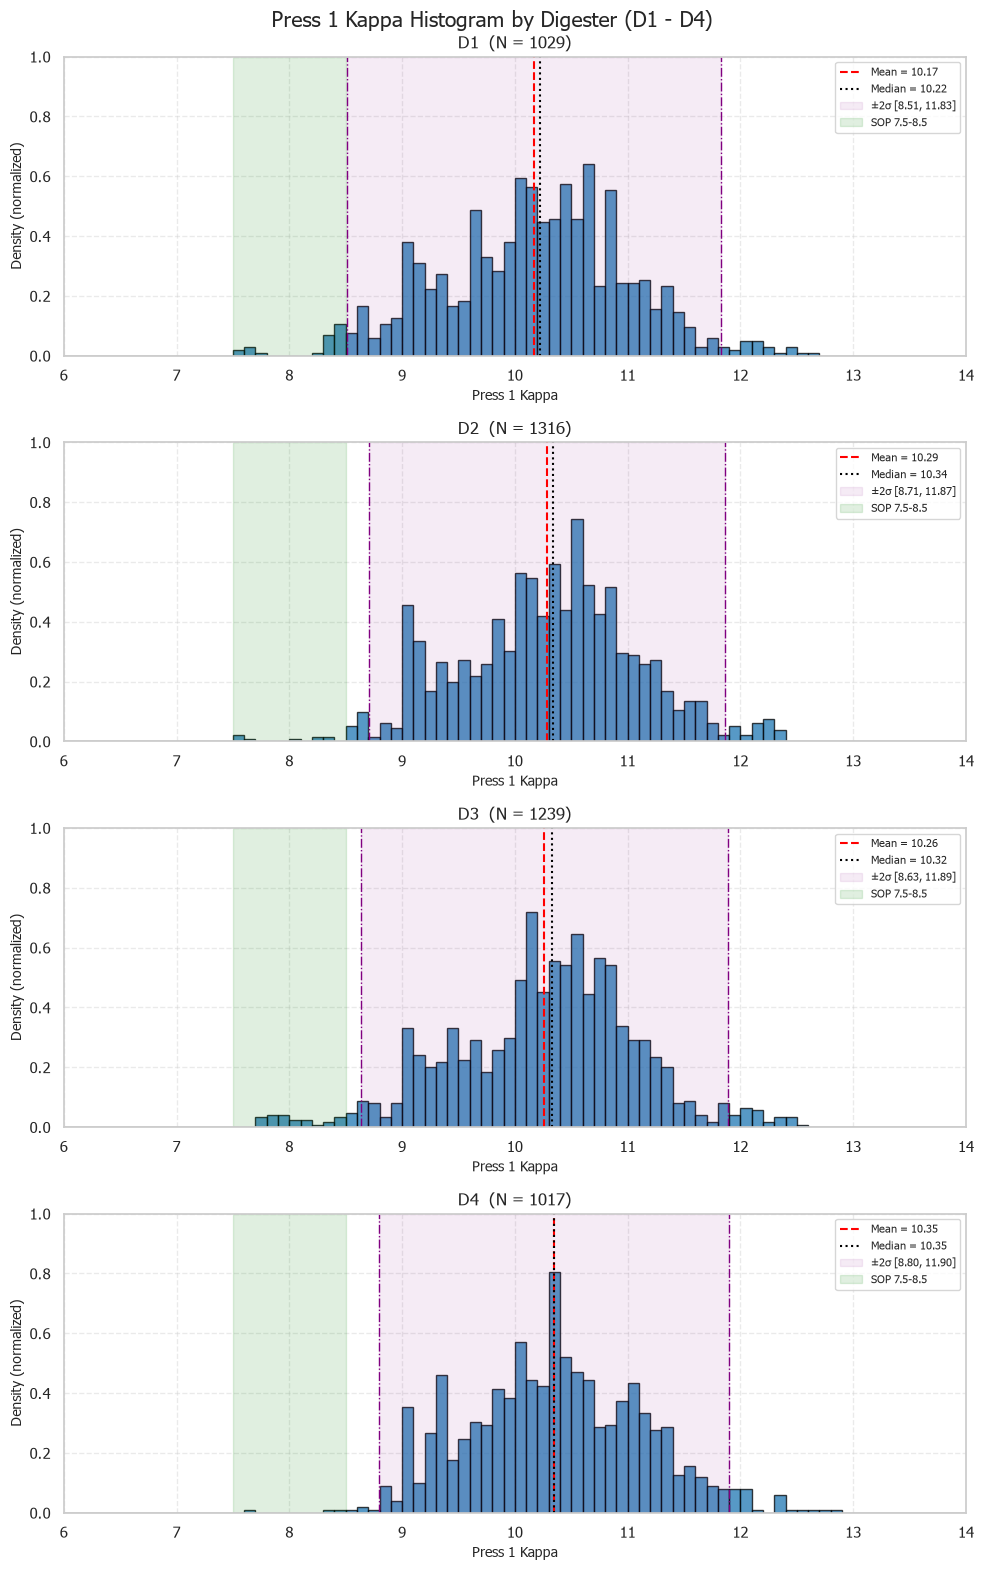

In [190]:
# Kappa Histogram — adjust KAPPA_XLIM to zoom the X-axis (None = auto)
# KAPPA_BIN_WIDTH sets the resolution (smaller = finer).
KAPPA_XLIM = (6, 14)
KAPPA_YLIM = (0, 1)  # density scale; e.g. (0, 1.2) to fix the Y-axis; None = auto
KAPPA_BIN_WIDTH = 0.1
import numpy as np
_kvals = df_wide[kappa_col].dropna()
_lo, _hi = (KAPPA_XLIM if KAPPA_XLIM else (_kvals.min(), _kvals.max()))
kappa_bins = np.arange(_lo, _hi + KAPPA_BIN_WIDTH, KAPPA_BIN_WIDTH)
plot_quality_hist_by_digester(kappa_col, 'Press 1 Kappa', '#1f77b4', xlim=KAPPA_XLIM, ylim=KAPPA_YLIM, bins=kappa_bins, density=True)


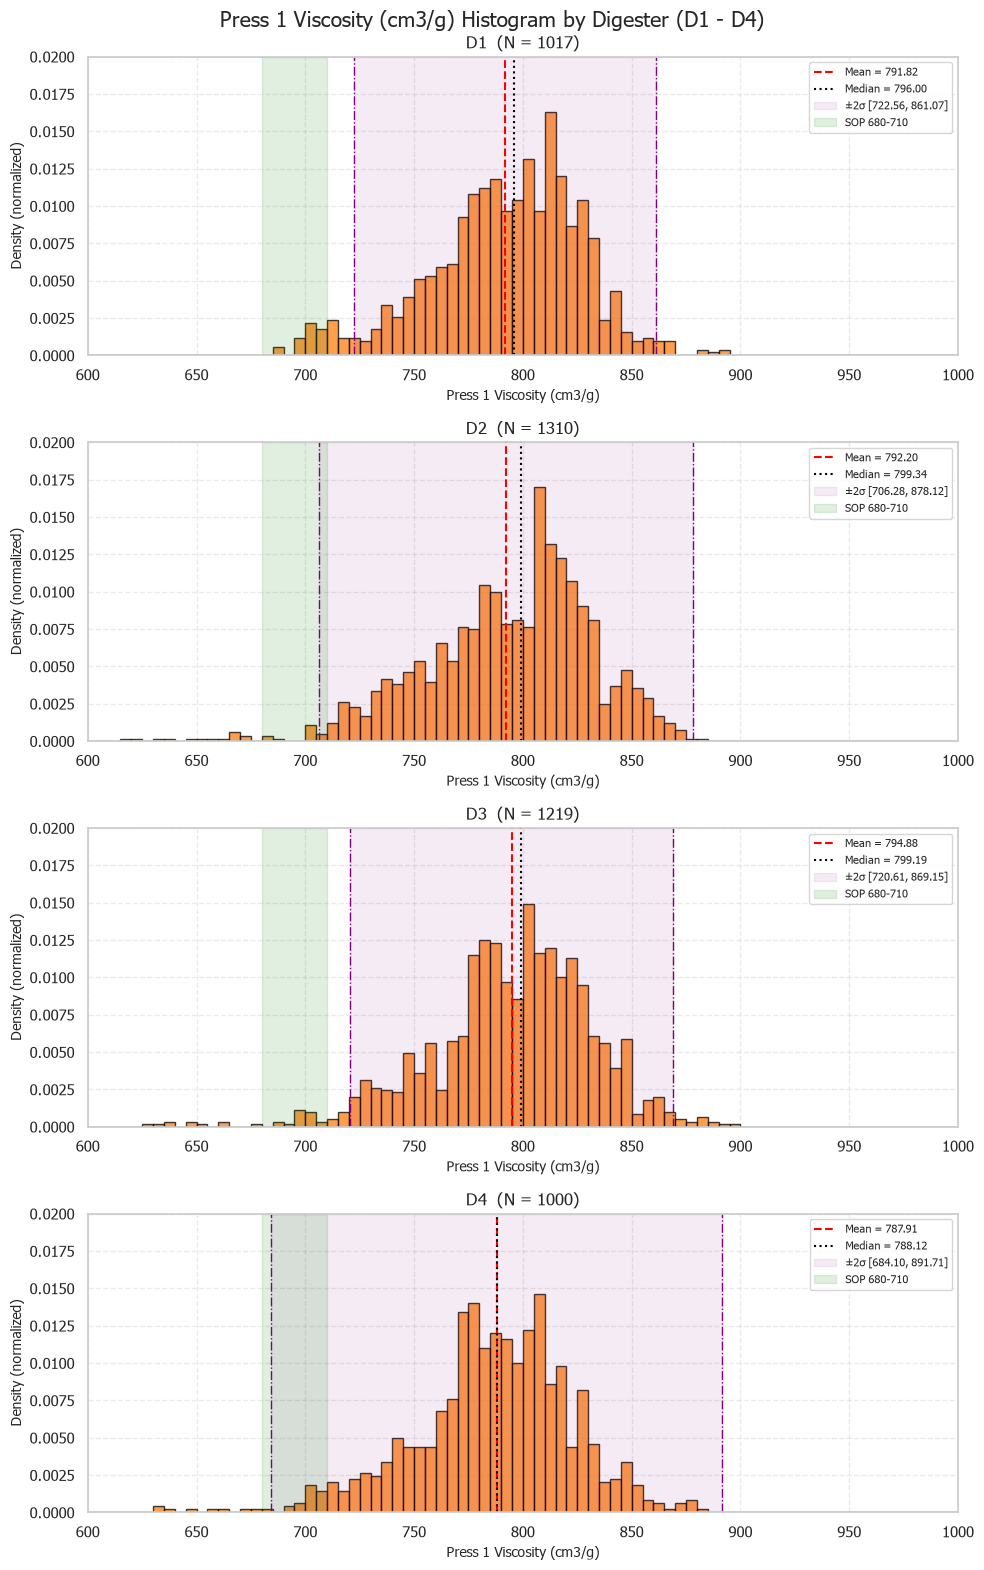

In [191]:
# Viscosity Histogram — adjust VISC_XLIM to zoom the X-axis (None = auto)
# VISC_BIN_WIDTH sets the resolution (smaller = finer).
VISC_XLIM = (600, 1000)
VISC_YLIM = (0, 0.02)  # density scale; e.g. (0, 0.02) to fix the Y-axis; None = auto
VISC_BIN_WIDTH = 5
import numpy as np
_vvals = df_wide[visc_col].dropna()
_vvals = _vvals[(_vvals >= 400) & (_vvals <= 2000)]
_lo, _hi = (VISC_XLIM if VISC_XLIM else (_vvals.min(), _vvals.max()))
visc_bins = np.arange(_lo, _hi + VISC_BIN_WIDTH, VISC_BIN_WIDTH)
plot_quality_hist_by_digester(visc_col, 'Press 1 Viscosity (cm3/g)', '#ff7f0e', xlim=VISC_XLIM, ylim=VISC_YLIM, filter_lo=400, filter_hi=2000, bins=visc_bins, density=True)


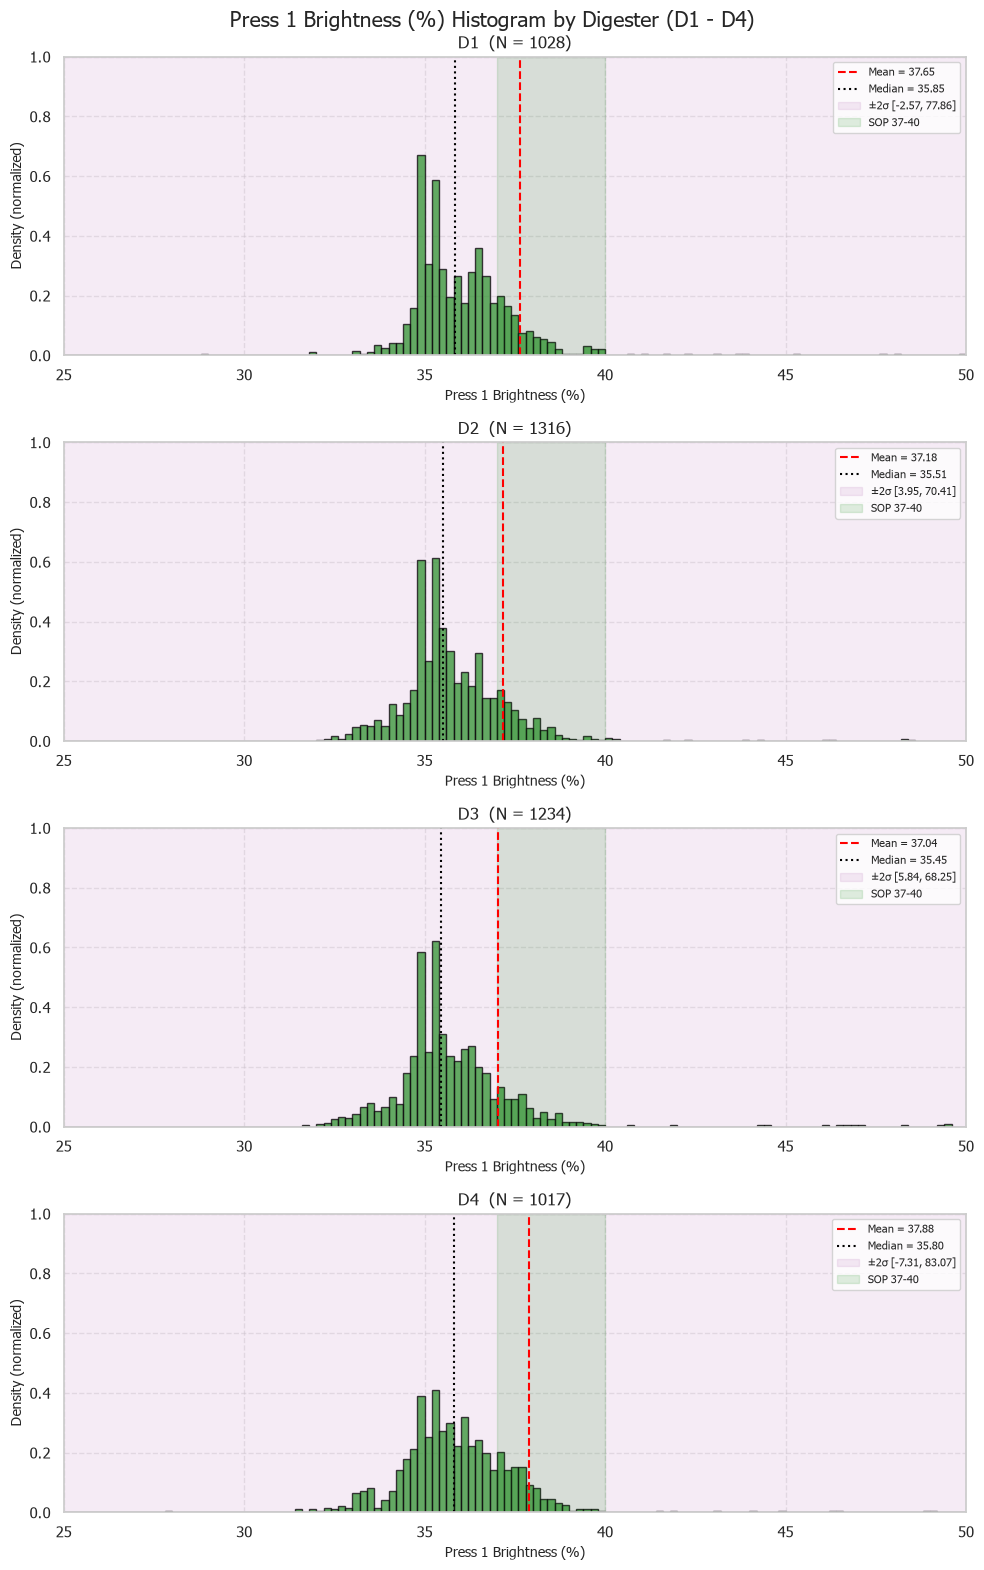

In [192]:
# Brightness Histogram — adjust BRIGHT_XLIM to zoom the X-axis (None = auto)
# BRIGHT_BIN_WIDTH sets the resolution (smaller = finer). 0.2 shows detail around the ~0.5 rounding grid.
BRIGHT_XLIM = (25, 50)
BRIGHT_YLIM = (0, 1)  # density scale; e.g. (0, 0.5) to fix the Y-axis; None = auto
BRIGHT_BIN_WIDTH = 0.2
import numpy as np
_bvals = df_wide[bright_col].dropna()
_lo, _hi = (BRIGHT_XLIM if BRIGHT_XLIM else (_bvals.min(), _bvals.max()))
bright_bins = np.arange(_lo, _hi + BRIGHT_BIN_WIDTH, BRIGHT_BIN_WIDTH)
plot_quality_hist_by_digester(bright_col, 'Press 1 Brightness (%)', '#2ca02c', xlim=BRIGHT_XLIM, ylim=BRIGHT_YLIM, bins=bright_bins, density=True)


### 5b. Lab Quality Boxplots by Digester (D1 - D4)

Box plots compare the spread, median, quartiles (IQR) and outliers of each lab metric across digesters on a single axis, with the SOP band overlaid for reference.


In [193]:
# Reusable helper: boxplot of one parameter split by Digester (D1-D4) with SOP band
def plot_quality_box_by_digester(col, label, color, ylim=None, filter_lo=None, filter_hi=None, showfliers=True):
    if not col or col not in df_wide.columns or 'Digester_ID' not in df_wide.columns:
        print(f" {label} column or Digester_ID not found in dataset.")
        return

    digester_order = [1, 2, 3, 4]
    plot_df = df_wide[['Digester_ID', col]].dropna()
    plot_df['Digester_ID'] = plot_df['Digester_ID'].astype(int)  # float 1.0 would not match order [1, 2, 3, 4]
    if filter_lo is not None and filter_hi is not None:
        plot_df = plot_df[(plot_df[col] >= filter_lo) & (plot_df[col] <= filter_hi)]  # drop sensor spikes

    plt.figure(figsize=(10, 6))
    if col in LAB_SOP_LIMITS:
        sop_lo, sop_hi = LAB_SOP_LIMITS[col]
        plt.axhspan(sop_lo, sop_hi, color='green', alpha=0.12, label=f'SOP {sop_lo}-{sop_hi}')

    ax = sns.boxplot(data=plot_df, x='Digester_ID', y=col, order=digester_order,
                     color=color, showfliers=showfliers, width=0.6)
    ax.set_xticklabels([f'D{i}' for i in digester_order])

    # Annotate median value above each box
    for i, dig in enumerate(digester_order):
        dvals = plot_df[plot_df['Digester_ID'] == dig][col]
        if len(dvals) > 0:
            ax.text(i, dvals.median(), f'{dvals.median():.2f}', ha='center', va='bottom',
                    fontsize=9, fontweight='bold', color='black')

    if ylim is not None:
        plt.ylim(ylim)

    plt.title(f'{label} Boxplot by Digester (D1 - D4)', fontsize=14, fontweight='normal')
    plt.xlabel('Digester ID', fontsize=11)
    plt.ylabel(label, fontsize=11)
    plt.legend(fontsize=9)
    plt.grid(True, axis='y', linestyle='--', alpha=0.4)
    plt.tight_layout()
    plt.show()


C:\Users\chinnput\AppData\Local\Temp\5\ipykernel_74624\453876671.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([f'D{i}' for i in digester_order])


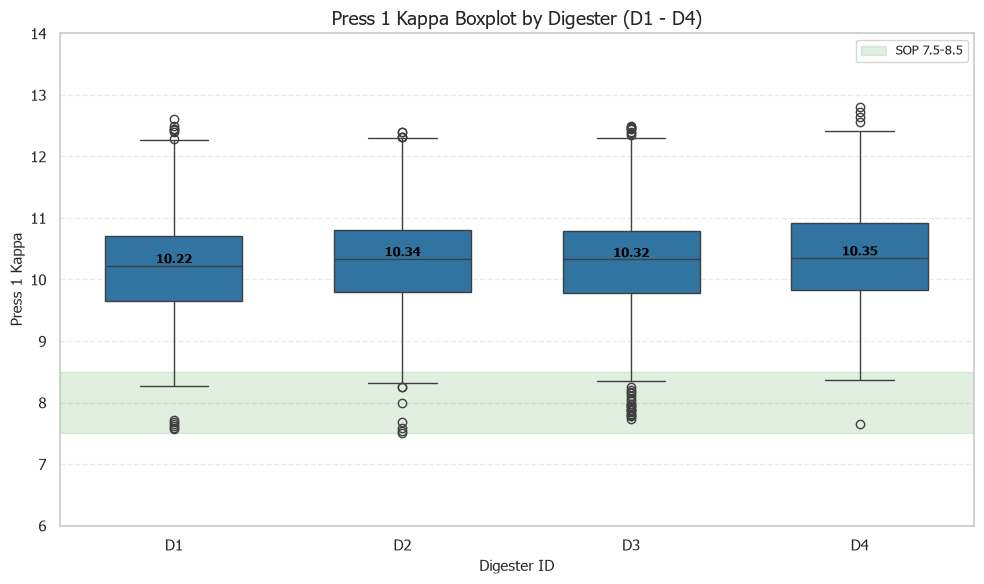

In [194]:
# Kappa Boxplot by Digester — adjust KAPPA_BOX_YLIM to zoom the Y-axis (None = auto)
KAPPA_BOX_YLIM = (6, 14)
plot_quality_box_by_digester(kappa_col, 'Press 1 Kappa', '#1f77b4', ylim=KAPPA_BOX_YLIM)


C:\Users\chinnput\AppData\Local\Temp\5\ipykernel_74624\453876671.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([f'D{i}' for i in digester_order])


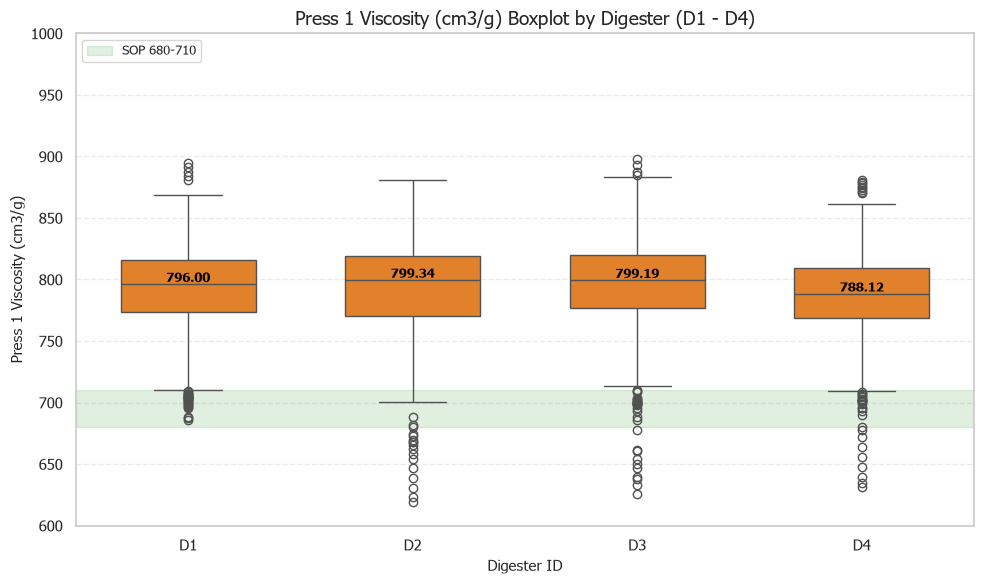

In [195]:
# Viscosity Boxplot by Digester — adjust VISC_BOX_YLIM to zoom the Y-axis (None = auto)
VISC_BOX_YLIM = (600, 1000)
plot_quality_box_by_digester(visc_col, 'Press 1 Viscosity (cm3/g)', '#ff7f0e', ylim=VISC_BOX_YLIM, filter_lo=400, filter_hi=2000)


C:\Users\chinnput\AppData\Local\Temp\5\ipykernel_74624\453876671.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([f'D{i}' for i in digester_order])


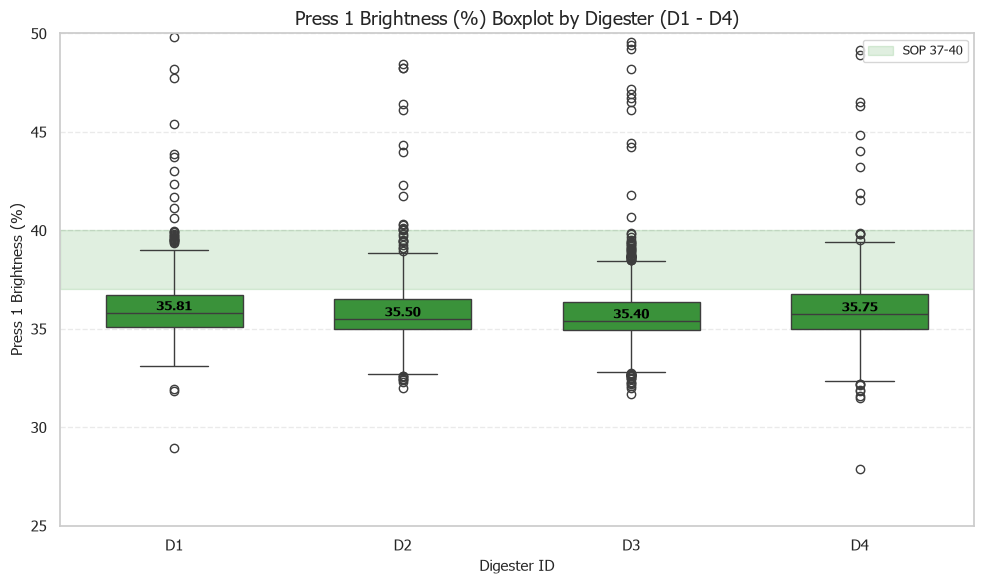

In [196]:
# Brightness Boxplot by Digester — adjust BRIGHT_BOX_YLIM to zoom the Y-axis (None = auto)
BRIGHT_BOX_YLIM = (25, 50)
plot_quality_box_by_digester(bright_col, 'Press 1 Brightness (%)', '#2ca02c', ylim=BRIGHT_BOX_YLIM, filter_lo=25, filter_hi=50)


### 5c. Process Consistency: Standard Deviation & CV% by Digester

Standard Deviation (SD) measures how much each lab metric varies within a digester — **lower SD = more consistent process control**.
Because the three metrics use different units/scales, the right chart shows **Coefficient of Variation (CV% = SD / Mean × 100)**, a unit-free measure that lets you compare relative variability across Kappa, Viscosity and Brightness on one axis.


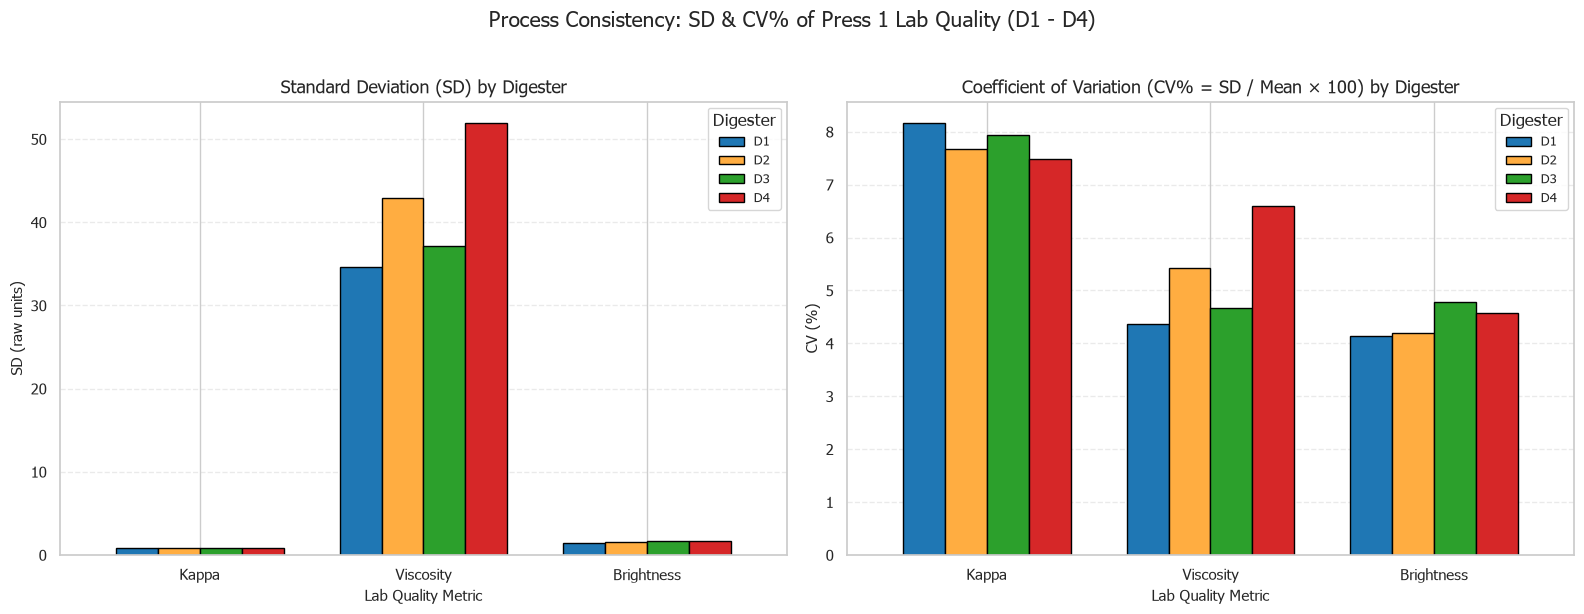

Standard Deviation (raw units):


,1,2,3,4
Kappa,0.83,0.79,0.81,0.78
Viscosity,34.63,42.96,37.13,51.90
Brightness,1.49,1.50,1.71,1.64



Coefficient of Variation (CV %):


,1,2,3,4
Kappa,8.16,7.67,7.94,7.49
Viscosity,4.37,5.42,4.67,6.59
Brightness,4.14,4.20,4.78,4.57


In [197]:
# Standard Deviation (SD) & Coefficient of Variation (CV%) of lab quality per Digester
LAB_TAGS_SD = {
    kappa_col: 'Kappa',
    visc_col: 'Viscosity',
    bright_col: 'Brightness',
}
# Filter ranges to drop sensor spikes before computing SD (None = no filter)
SD_FILTERS = {
    visc_col: (400, 2000),
    bright_col: (25, 50),
}

digester_order = [1, 2, 3, 4]
sd_records, cv_records = {}, {}
for col, name in LAB_TAGS_SD.items():
    if not col or col not in df_wide.columns:
        continue
    sd_row, cv_row = {}, {}
    for dig in digester_order:
        vals = df_wide[df_wide['Digester_ID'] == dig][col].dropna()
        if col in SD_FILTERS:
            flo, fhi = SD_FILTERS[col]
            vals = vals[(vals >= flo) & (vals <= fhi)]
        if len(vals) > 1:
            sd_row[dig] = vals.std()
            cv_row[dig] = (vals.std() / vals.mean() * 100) if vals.mean() != 0 else np.nan
        else:
            sd_row[dig], cv_row[dig] = np.nan, np.nan
    sd_records[name] = sd_row
    cv_records[name] = cv_row

sd_df = pd.DataFrame(sd_records).T[digester_order]
cv_df = pd.DataFrame(cv_records).T[digester_order]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
bar_palette = ['#1f77b4', '#ffad41', '#2ca02c', '#d62728']

# Rename columns for plotting legend
sd_df_plot = sd_df.rename(columns=lambda x: f'D{x}')
cv_df_plot = cv_df.rename(columns=lambda x: f'D{x}')


sd_df_plot.plot(kind='bar', ax=axes[0], color=bar_palette, edgecolor='black', width=0.75)
axes[0].set_title('Standard Deviation (SD) by Digester', fontsize=13)
axes[0].set_xlabel('Lab Quality Metric', fontsize=11)
axes[0].set_ylabel('SD (raw units)', fontsize=11)
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(title='Digester', fontsize=9)
axes[0].grid(True, axis='y', linestyle='--', alpha=0.4)

cv_df_plot.plot(kind='bar', ax=axes[1], color=bar_palette, edgecolor='black', width=0.75)
axes[1].set_title('Coefficient of Variation (CV% = SD / Mean × 100) by Digester', fontsize=13)
axes[1].set_xlabel('Lab Quality Metric', fontsize=11)
axes[1].set_ylabel('CV (%)', fontsize=11)
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Digester', fontsize=9)
axes[1].grid(True, axis='y', linestyle='--', alpha=0.4)

plt.suptitle('Process Consistency: SD & CV% of Press 1 Lab Quality (D1 - D4)', fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

print("Standard Deviation (raw units):")
display(sd_df.round(2))
print("\nCoefficient of Variation (CV %):")
display(cv_df.round(2))


### 6. Digester Quality Benchmark & Statistical Matrix

In [198]:
# Calculate Mean and Standard Deviation (SD) per Digester (excluding status & metadata)
exclude_keywords = ['STATUS', 'CLUSTER', 'BLOCK_ID', 'ROW_COUNT', 'DURATION_MIN']
numeric_cols = [c for c in df_wide.columns if c not in ['timestamp', 'time', 'Digester_ID'] and not any(kw in c.upper() for kw in exclude_keywords)]

if 'Digester_ID' in df_wide.columns and len(numeric_cols) > 0:
    summary_matrix = df_wide.groupby('Digester_ID')[numeric_cols].agg(['mean', 'std']).T
    print("==========================================================================")
    print("       PRESS 1 QUALITY & PROCESS STATISTICAL BENCHMARK (D1 - D4)          ")
    print("==========================================================================")
    display(summary_matrix)
else:
    print(" Digester ID or numeric process parameters unavailable for aggregation.")

       PRESS 1 QUALITY & PROCESS STATISTICAL BENCHMARK (D1 - D4)          


Digester_ID                                       1.0         2.0         3.0  \
tag                                                                             
PM2.105FIC303:MV                     mean    1.649189    1.697334    1.671692   
                                     std     0.423700    0.385888    0.366998   
PM2.105NIC207:MV                     mean    3.743291    3.805209    3.825467   
                                     std     0.709821    0.536441    0.470001   
PM2.106FIC006:MV                     mean  514.989551  529.987623  527.400825   
                                     std   126.487666  102.555710   91.718360   
PM2.305FIC036:MV                     mean    0.983512    0.978306    0.991809   
                                     std     0.240025    0.249118    0.236467   
PM2.Prod.ODL                         mean  274.117186  278.303549  278.470634   
                                     std    58.179939   47.193744   42.722117   
PULP-LINE2-BRIGHTNESS-PRESS1         mean   37.645191   37.178465   37.043834   
                                     std    20.109224   16.613457   15.601506   
PULP-LINE2-KAPPA-PRESS1              mean   10.168225   10.288717   10.262608   
                                     std     0.829794    0.789392    0.814453   
PULP-LINE2-VISCOSITY-PRESS1          mean  826.368923  824.046119  826.956920   
                                     std   500.738748  473.196292  386.052421   
Specific WHLiqu Consumption (m3_ADT) mean    0.198388    0.208320    0.186494   
                                     std     0.475367    0.815395    0.790805   
Specific Steam Consumption (t_ADT)   mean    0.344417    0.299142    2.013904   
                                     std     1.870879    2.168587   58.387131   

Digester_ID                                       4.0  
tag                                                    
PM2.105FIC303:MV                     mean    1.856867  
                                     std     0.362916  
PM2.105NIC207:MV                     mean    3.818222  
                                     std     0.467628  
PM2.106FIC006:MV                     mean  562.397496  
                                     std    91.674826  
PM2.305FIC036:MV                     mean    0.906799  
                                     std     0.241781  
PM2.Prod.ODL                         mean  289.855388  
                                     std    43.986143  
PULP-LINE2-BRIGHTNESS-PRESS1         mean   37.883869  
                                     std    22.594504  
PULP-LINE2-KAPPA-PRESS1              mean   10.349456  
                                     std     0.775269  
PULP-LINE2-VISCOSITY-PRESS1          mean  838.744972  
                                     std   522.335231  
Specific WHLiqu Consumption (m3_ADT) mean    0.146387  
                                     std     0.365444  
Specific Steam Consumption (t_ADT)   mean    0.647259  
                                     std    14.325243

### 7. Press 1 & Process Parameter Heatmap by Digester

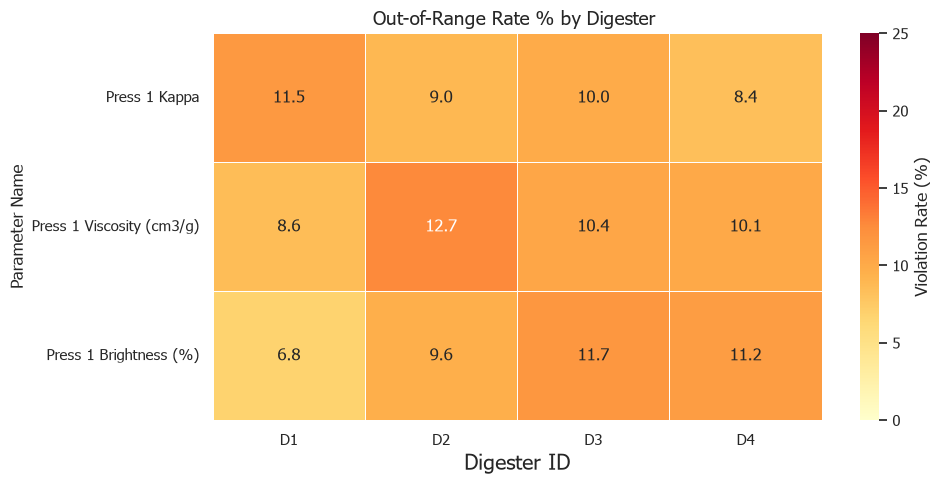

In [199]:
# 2. Plot Process Variation Heatmap: SOP Violation Rate % by Digester

# Friendly Name Mapping for PI Tags & Process Parameters
TAG_LABELS = {
    "PM2.105FIC303:MV": "White Liquor Flow (m3/h)",
    "PM2.305FIC036:MV": "MP Steam Flow (t/h)",
    "PM2.Prod.ODL": "Production ODL (ADT/D)",
    "PM2.105NIC207:MV": "Press 1 Feed Cons (%)",
    "PM2.106FIC006:MV": "Deknotting Feed Flow (m3/h)",
    "Specific WHLiqu Consumption (m3_ADT)": "Specific White Liquor (m3/ADT)",
    "Specific Steam Consumption (t_ADT)": "Specific Steam (t/ADT)",
    "PULP-LINE2-KAPPA-PRESS1": "Press 1 Kappa",
    "PULP-LINE2-VISCOSITY-PRESS1": "Press 1 Viscosity (cm3/g)",
    "PULP-LINE2-BRIGHTNESS-PRESS1": "Press 1 Brightness (%)",
    # Mappings for local fallback dataset
    "WHLiqu to DilSrew_White liquor (m3/h)_mean": "White Liquor Flow (m3/h)",
    "MP Steam Pulp Heat_Feed before Reactor 2 (t/h)_mean": "MP Steam Flow (t/h)",
    "Production ODL (ADT/D)_mean": "Production ODL (ADT/D)",
    "Press 1 Feed Cons (%)_mean": "Press 1 Feed Cons (%)",
    "Deknotting Feed Flow (m3/h)_mean": "Deknotting Feed Flow (m3/h)",
    "Specific WHLiqu Consumption (m3_ADT)_mean": "Specific White Liquor (m3/ADT)",
    "Specific Steam Consumption (t_ADT)_mean": "Specific Steam (t/ADT)",
    "Pre O2 Kappa_Kappa online (%)_mean": "Pre O2 Kappa Online",
    "Post O2 Kappa_Kappa online (%)_mean": "Post O2 Kappa Online"
}

if 'Digester_ID' in df_wide.columns:
    numeric_df = df_wide.select_dtypes(include=[np.number]).copy()
    numeric_df['Digester_ID'] = df_wide['Digester_ID']
    
    # -------------------------------------------------------------
    # Select the specific Parameters or Tags to display in the Heatmap
    # You can add/remove entries in the SELECTED_HEATMAP_TAGS list as needed
    # -------------------------------------------------------------
    SELECTED_HEATMAP_TAGS = [
        # Lab Quality Outputs (primary quality parameters)
        "PULP-LINE2-KAPPA-PRESS1",
        "PULP-LINE2-VISCOSITY-PRESS1",
        "PULP-LINE2-BRIGHTNESS-PRESS1",
        
        # # Specific Consumption (specific energy/chemical usage)
        # "Specific Steam Consumption (t_ADT)",
        # "Specific WHLiqu Consumption (m3_ADT)",
        
        # # Key Process DCS Parameters (main operating parameters)
        # "PM2.305FIC036:MV",   # MP Steam Flow
        # "PM2.105FIC303:MV",   # White Liquor Flow
        # "PM2.Prod.ODL",       # Production ODL
        # "PM2.105NIC207:MV",   # Press 1 Feed Cons
    ]
    
    # Keep only variables that exist in the df_wide dataset
    clean_params = [t for t in SELECTED_HEATMAP_TAGS if t in numeric_df.columns]
    
    # If none are configured, fall back to all numeric columns that are not metadata
    if len(clean_params) == 0:
        exclude_keywords = ['STATUS', 'CLUSTER', 'BLOCK_ID', 'ROW_COUNT', 'DURATION_MIN', '_STD']
        clean_params = [c for c in numeric_df.columns if c != 'Digester_ID' and not any(kw in c.upper() for kw in exclude_keywords)]
    
    # Spike filters to drop sensor false readings before computing percentiles
    PCTL_FILTERS = {
        "PULP-LINE2-VISCOSITY-PRESS1": (400, 2000),
        "PULP-LINE2-BRIGHTNESS-PRESS1": (25, 50),
    }

    # Out-of-range Rate (%) using each parameter's own 5th/95th percentile band
    # computed from the POOLED data (all digesters), so a digester that swings
    # more than the overall norm shows a higher %.
    violation_rates = {}
    for param in clean_params:
        valid_vals = numeric_df[param].dropna()
        if param in PCTL_FILTERS:
            flo, fhi = PCTL_FILTERS[param]
            valid_vals = valid_vals[(valid_vals >= flo) & (valid_vals <= fhi)]
        if len(valid_vals) == 0:
            continue
        low = valid_vals.quantile(0.05)
        high = valid_vals.quantile(0.95)

        param_rates = {}
        for dig in [1, 2, 3, 4]:
            dig_vals = numeric_df[numeric_df['Digester_ID'] == dig][param].dropna()
            if param in PCTL_FILTERS:
                flo, fhi = PCTL_FILTERS[param]
                dig_vals = dig_vals[(dig_vals >= flo) & (dig_vals <= fhi)]
            if len(dig_vals) > 0:
                violations = ((dig_vals < low) | (dig_vals > high)).sum()
                rate = (violations / len(dig_vals)) * 100
                param_rates[dig] = rate
            else:
                param_rates[dig] = np.nan
                
        # Clean & Convert tag to friendly readable label
        display_label = TAG_LABELS.get(param, param[:-5] if param.endswith('_mean') else param)
        violation_rates[display_label] = param_rates
        
    heatmap_data = pd.DataFrame(violation_rates).T
    col_order = [d for d in [1, 2, 3, 4] if d in heatmap_data.columns]
    heatmap_data = heatmap_data[col_order]
    heatmap_data.columns = [f'D{c}' for c in heatmap_data.columns]
    
    if not heatmap_data.empty:
        plt.figure(figsize=(10, max(5, len(heatmap_data) * 0.55)))
        sns.heatmap(
            heatmap_data,
            annot=True,
            fmt=".1f",
            cmap="YlOrRd",
            vmin=0,
            vmax=25,
            linewidths=0.5,
            cbar_kws={'label': 'Violation Rate (%)'}
        )
        plt.title('Out-of-Range Rate % by Digester ', fontsize=14, fontweight='normal')
        plt.xlabel('Digester ID', fontsize=15, fontweight='normal')
        plt.ylabel('Parameter Name', fontsize=12, fontweight='normal')
        plt.tight_layout()
        plt.show()
    else:
        print("No valid process parameters found for out-of-range heatmap plotting.")
else:
    print("Digester_ID column unavailable for heatmap plotting.")

### 7b. Diagnostic: Why does the SOP heatmap flag D4 as "bad" while the lab results look normal?

The section-7 heatmap counts how often each value falls **outside the SOP band**, then colors the result with a cropped scale (`vmin=85, vmax=100`). Two things distort it:

1. **The SOP limits are far from the real operating level** (e.g. Kappa SOP 7.5-8.5 but real mean ≈ 10) — so *every* digester shows a very high violation %, and tiny differences get exaggerated by the cropped color scale.
2. **D4 has far fewer samples than D1** — a handful of points swings its % more than the others.

This cell proves both: it shows the sample count (N), the **uncropped** violation rate (0-100), and how each digester's mean compares to the SOP band. Use this to decide whether the SOP limits need updating.


========== SOP HEATMAP DIAGNOSTIC ==========
If 'Mean_vs_SOP_gap' is large for ALL digesters, the SOP limits are set far from the
real operating level, so the heatmap flags high violations everywhere (not a real D4 problem).


,Metric,Digester,N,Mean,SOP_Low,SOP_High,Mean_vs_SOP_gap,Violation_%
0,Kappa,D1,1029,10.17,7.5,8.5,1.67,97.3
1,Kappa,D2,1316,10.29,7.5,8.5,1.79,99.2
2,Kappa,D3,1239,10.26,7.5,8.5,1.76,97.7
3,Kappa,D4,1017,10.35,7.5,8.5,1.85,99.7
4,Viscosity,D1,1017,791.82,680.0,710.0,81.82,97.1
5,Viscosity,D2,1310,792.20,680.0,710.0,82.20,99.0
6,Viscosity,D3,1219,794.88,680.0,710.0,84.88,98.5
7,Viscosity,D4,1000,787.91,680.0,710.0,77.91,97.7
8,Brightness,D1,1028,37.65,37.0,40.0,0.00,82.1
9,Brightness,D2,1316,37.18,37.0,40.0,0.00,85.1



Sample count (N) per Digester:


,N
Digester_ID,
D1,1029
D2,1316
D3,1239
D4,1017


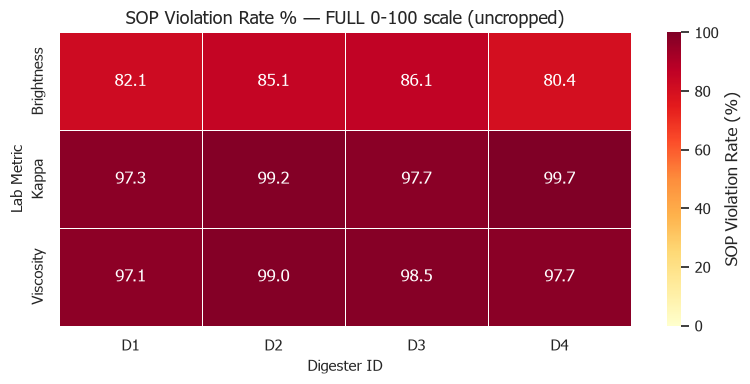

In [200]:
# Diagnostic: expose why the SOP heatmap disagrees with the real lab results
LAB_DIAG_TAGS = {
    "PULP-LINE2-KAPPA-PRESS1": "Kappa",
    "PULP-LINE2-VISCOSITY-PRESS1": "Viscosity",
    "PULP-LINE2-BRIGHTNESS-PRESS1": "Brightness",
}
DIAG_FILTERS = {"PULP-LINE2-VISCOSITY-PRESS1": (400, 2000)}  # drop sensor spikes
digester_order = [1, 2, 3, 4]

rows = []
for tag, name in LAB_DIAG_TAGS.items():
    if tag not in df_wide.columns:
        continue
    sop_lo, sop_hi = LAB_SOP_LIMITS.get(tag, (np.nan, np.nan))
    for dig in digester_order:
        vals = df_wide[df_wide['Digester_ID'] == dig][tag].dropna()
        if tag in DIAG_FILTERS:
            flo, fhi = DIAG_FILTERS[tag]
            vals = vals[(vals >= flo) & (vals <= fhi)]
        n = len(vals)
        if n == 0:
            continue
        mean = vals.mean()
        viol = ((vals < sop_lo) | (vals > sop_hi)).mean() * 100
        # how far the mean sits outside the SOP band, in raw units
        gap = 0.0
        if mean < sop_lo:
            gap = mean - sop_lo
        elif mean > sop_hi:
            gap = mean - sop_hi
        rows.append({
            'Metric': name, 'Digester': f'D{dig}', 'N': n, 'Mean': round(mean, 2),
            'SOP_Low': sop_lo, 'SOP_High': sop_hi,
            'Mean_vs_SOP_gap': round(gap, 2), 'Violation_%': round(viol, 1),
        })

diag_df = pd.DataFrame(rows)
print("========== SOP HEATMAP DIAGNOSTIC ==========")
print("If 'Mean_vs_SOP_gap' is large for ALL digesters, the SOP limits are set far from the")
print("real operating level, so the heatmap flags high violations everywhere (not a real D4 problem).")
display(diag_df)

# Sample count per digester — small N makes D4's % noisy/unstable
print("\nSample count (N) per Digester:")
display(df_wide['Digester_ID'].value_counts().sort_index().to_frame('N').rename(index=lambda x: f'D{int(x)}'))

# Violation-rate heatmap on a FULL 0-100 scale (not cropped 85-100)
digester_label_order = [f'D{i}' for i in digester_order]
viol_pivot = diag_df.pivot(index='Metric', columns='Digester', values='Violation_%')[
    [d for d in digester_label_order if d in diag_df['Digester'].unique()]
]
plt.figure(figsize=(8, 4))
sns.heatmap(viol_pivot, annot=True, fmt=".1f", cmap="YlOrRd", vmin=0, vmax=100,
            linewidths=0.5, cbar_kws={'label': 'SOP Violation Rate (%)'})
plt.title('SOP Violation Rate % — FULL 0-100 scale (uncropped)', fontsize=13)
plt.xlabel('Digester ID', fontsize=11)
plt.ylabel('Lab Metric', fontsize=11)
plt.tight_layout()
plt.show()


### 8. Press 1 QA Lab Quality Mean & Median Benchmark by Digester

Compare the central tendency of lab results (Kappa, Viscosity, Brightness) per digester (D1 - D4) using two side-by-side heatmaps:
* **Left (Mean):** Arithmetic average, reflecting overall operating level (sensitive to outliers).
* **Right (Median):** Middle value, reflecting the true center (robust to outliers).


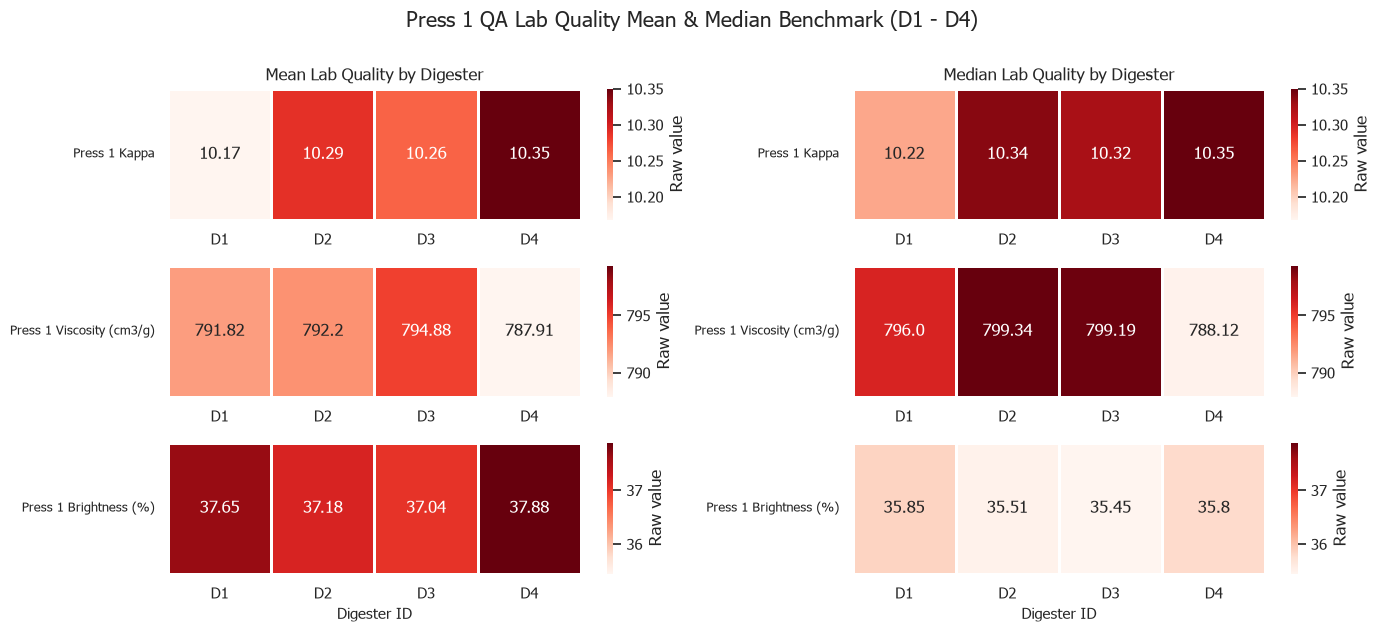

        PRESS 1 QA LAB QUALITY MEAN & MEDIAN BENCHMARK (D1 - D4)          


Mean                          Median          \
                               D1      D2      D3      D4      D1      D2   
Press 1 Kappa               10.17   10.29   10.26   10.35   10.22   10.34   
Press 1 Viscosity (cm3/g)  791.82  792.20  794.88  787.91  796.00  799.34   
Press 1 Brightness (%)      37.65   37.18   37.04   37.88   35.85   35.51   

                                           
                               D3      D4  
Press 1 Kappa               10.32   10.35  
Press 1 Viscosity (cm3/g)  799.19  788.12  
Press 1 Brightness (%)      35.45   35.80

In [201]:
# Press 1 Lab Quality Mean & Median Heatmaps compared across Digesters (D1 - D4)
LAB_QUALITY_TAGS = {
    "PULP-LINE2-KAPPA-PRESS1": "Press 1 Kappa",
    "PULP-LINE2-VISCOSITY-PRESS1": "Press 1 Viscosity (cm3/g)",
    "PULP-LINE2-BRIGHTNESS-PRESS1": "Press 1 Brightness (%)"
}

if 'Digester_ID' in df_wide.columns:
    digesters = [1, 2, 3, 4]
    avail_lab_tags = {tag: name for tag, name in LAB_QUALITY_TAGS.items() if tag in df_wide.columns}

    if len(avail_lab_tags) >= 1:
        mean_dict = {}
        median_dict = {}

        for tag, name in avail_lab_tags.items():
            mean_rates = {}
            median_rates = {}
            for dig in digesters:
                dig_data = df_wide[df_wide['Digester_ID'] == dig][tag].dropna()
                # Remove sensor false spikes for viscosity before aggregating
                if "VISCOSITY" in tag:
                    dig_data = dig_data[(dig_data >= 400) & (dig_data <= 2000)]

                if len(dig_data) > 0:
                    mean_rates[dig] = dig_data.mean()
                    median_rates[dig] = dig_data.median()
                else:
                    mean_rates[dig] = np.nan
                    median_rates[dig] = np.nan

            mean_dict[name] = mean_rates
            median_dict[name] = median_rates

        df_mean = pd.DataFrame(mean_dict).T[digesters]
        df_median = pd.DataFrame(median_dict).T[digesters]
        
        # Rename columns for display
        df_mean.columns = [f'D{c}' for c in df_mean.columns]
        df_median.columns = [f'D{c}' for c in df_median.columns]

        params = list(df_mean.index)
        n_params = len(params)

        # Raw-value heatmaps: one row per parameter, each parameter has its own colorbar.
        # Mean (left) & Median (right) share the same scale per parameter (shared row min/max).
        fig, axes = plt.subplots(
            n_params, 2, figsize=(14, 1.6 * n_params + 1.5), squeeze=False
        )

        for r, param in enumerate(params):
            row_vals = pd.concat([df_mean.loc[param], df_median.loc[param]])
            vmin, vmax = row_vals.min(), row_vals.max()

            for c, (df_stat, stat_name) in enumerate(
                [(df_mean, 'Mean'), (df_median, 'Median')]
            ):
                ax = axes[r][c]
                cell = df_stat.loc[[param]]
                sns.heatmap(
                    cell,
                    annot=cell.round(2).astype(str),
                    fmt="",
                    cmap="Reds",
                    vmin=vmin,
                    vmax=vmax,
                    linewidths=0.8,
                    cbar=True,
                    cbar_kws={'label': 'Raw value'},
                    ax=ax
                )
                ax.set_ylabel('')
                ax.set_yticklabels([param], rotation=0, fontsize=9)
                if r == 0:
                    ax.set_title(f'{stat_name} Lab Quality by Digester', fontsize=12)
                ax.set_xlabel('Digester ID' if r == n_params - 1 else '', fontsize=11)

        plt.suptitle('Press 1 QA Lab Quality Mean & Median Benchmark (D1 - D4)', fontsize=15, y=1.0)
        plt.tight_layout()
        plt.show()

        # Display combined statistical table
        df_combined = pd.concat(
            {'Mean': df_mean, 'Median': df_median}, axis=1
        )
        print("=========================================================================")
        print("        PRESS 1 QA LAB QUALITY MEAN & MEDIAN BENCHMARK (D1 - D4)          ")
        print("=========================================================================")
        display(df_combined.round(2))
    else:
        print("No Press 1 lab quality tags available in dataset for Mean/Median benchmark.")
else:
    print("Digester_ID column unavailable for Mean/Median benchmark.")


### 9. Digester-Specific Correlation Breakdown (D1, D2, D3, D4)

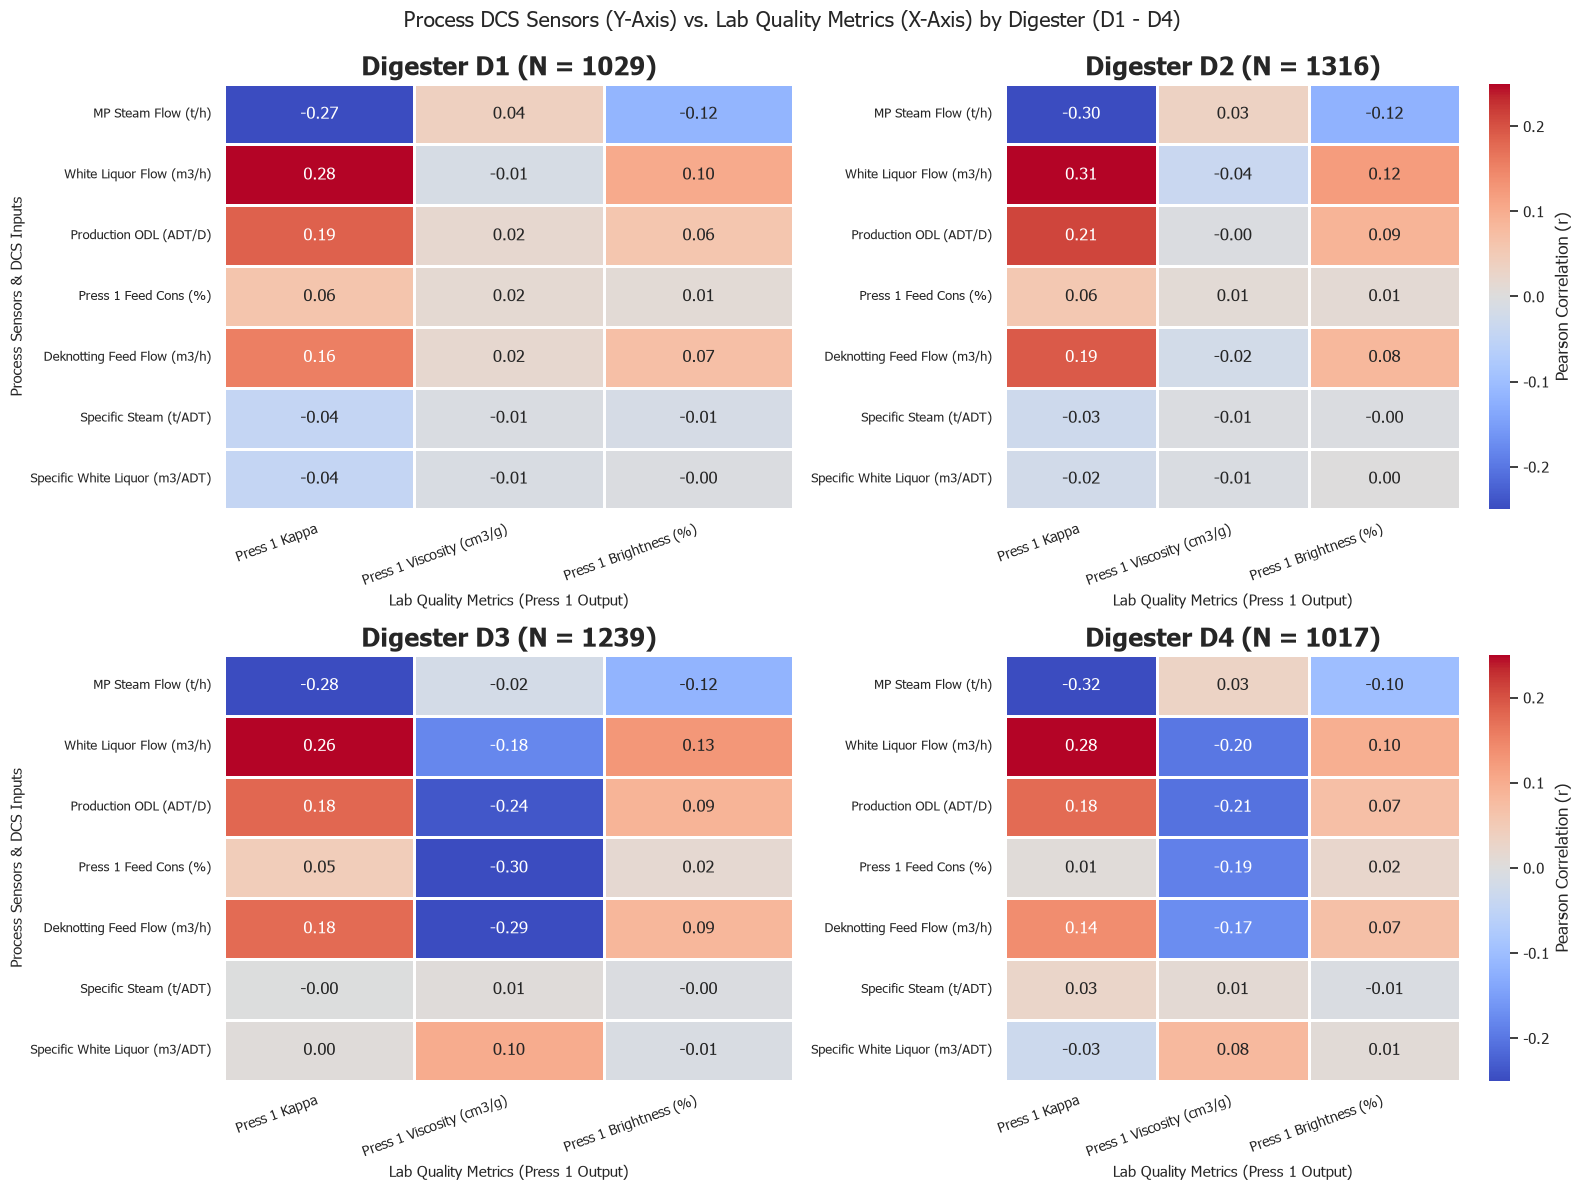

In [202]:
# Plot Digester-Specific Rectangular Cross-Correlation Matrices (Process Sensors vs. Lab Quality)
process_inputs = [
    "PM2.305FIC036:MV",                       # MP Steam Flow
    "PM2.105FIC303:MV",                       # White Liquor Flow
    "PM2.Prod.ODL",                           # Production ODL
    "PM2.105NIC207:MV",                       # Press 1 Feed Cons
    "PM2.106FIC006:MV",                       # Deknotting Feed Flow
    "Specific Steam Consumption (t_ADT)",     # Specific Steam
    "Specific WHLiqu Consumption (m3_ADT)"    # Specific White Liquor
]

lab_outputs = [
    "PULP-LINE2-KAPPA-PRESS1",       # Press 1 Kappa
    "PULP-LINE2-VISCOSITY-PRESS1",   # Press 1 Viscosity
    "PULP-LINE2-BRIGHTNESS-PRESS1"   # Press 1 Brightness
]

# Filter available columns
avail_proc = [c for c in process_inputs if c in df_wide.columns]
avail_lab = [c for c in lab_outputs if c in df_wide.columns]

if 'Digester_ID' in df_wide.columns and len(avail_proc) >= 2 and len(avail_lab) >= 1:
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    axes = axes.flatten()
    digester_list = [1, 2, 3, 4]
    
    for idx, dig in enumerate(digester_list):
        ax = axes[idx]
        df_sub = df_wide[df_wide['Digester_ID'] == dig].dropna(how='all')
        
        if len(df_sub) > 5:
            # Compute rectangular cross-correlation: Rows = Process Inputs, Cols = Lab Outputs
            cross_corr = pd.DataFrame(index=avail_proc, columns=avail_lab, dtype=float)
            for p in avail_proc:
                for l in avail_lab:
                    cross_corr.loc[p, l] = df_sub[p].corr(df_sub[l])
            
            # Rename index and columns to friendly labels
            cross_corr_renamed = cross_corr.rename(index=TAG_LABELS, columns=TAG_LABELS)
            
            sns.heatmap(
                cross_corr_renamed,
                annot=True,
                fmt=".2f",
                cmap="coolwarm",
                vmin=-0.25,
                vmax=0.25,
                linewidths=0.8,
                cbar=(idx == 1 or idx == 3),
                cbar_kws={'label': 'Pearson Correlation (r)'} if (idx == 1 or idx == 3) else None,
                ax=ax
            )
            ax.set_title(f'Digester D{dig} (N = {len(df_sub)})', fontsize=18, fontweight='bold')
            ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha='right', fontsize=10)
            ax.set_yticklabels(ax.get_yticklabels(), fontsize=9)
            ax.set_xlabel('Lab Quality Metrics (Press 1 Output)', fontsize=11)
            ax.set_ylabel('Process Sensors & DCS Inputs' if (idx == 0 or idx == 2) else '', fontsize=11)
        else:
            ax.text(0.5, 0.5, f'Insufficient Data for D{dig}\n(N = {len(df_sub)})', 
                    ha='center', va='center', fontsize=12, color='gray')
            ax.set_title(f'Digester D{dig} (No Data)', fontsize=18, fontweight='bold')
            ax.axis('off')
            
    plt.suptitle('Process DCS Sensors (Y-Axis) vs. Lab Quality Metrics (X-Axis) by Digester (D1 - D4)', fontsize=15, y=0.99)
    plt.tight_layout()
    plt.show()
else:
    print("⚠️ Digester_ID or required process/lab columns unavailable for rectangular cross-correlation.")
